In [1]:
import pyreadstat
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
FICHIER_SAV = r"F:\Mémoire_pris_au_Sérieux\Base Producteurs IDID 2013 V3.sav"
df, meta = pyreadstat.read_sav(FICHIER_SAV)

# 10 sources : les 8 d'origine + Internet + Journaux
sources = ['cecp','ong','coop','four','vois','radio','tele','fone','int','jour']

# ---- Utilisation (l = bonne variable) ----
vars_util = ['l'+s for s in sources]
for v in vars_util:
    df[v] = df[v].fillna(0)
    df[v] = (df[v] > 0).astype(float)
df['utilisation_info'] = (df[vars_util].sum(axis=1) > 0).astype(float)

# ---- Réalisme perçu (u = bonne variable) ----
vars_real = ['u'+s for s in sources]
for v in vars_real:
    df[v] = df[v].fillna(0)
df['realisme_percu'] = (df[vars_real].sum(axis=1) > 0).astype(float)

# ---- Accessibilité ----
vars_acces = ['s'+s for s in sources]
df['accessibilite'] = (df[vars_acces].sum(axis=1) > 0).astype(float)

# ---- Fréquence de réception (a = bonne variable) ----
vars_freq = ['a'+s for s in sources]
def get_freq(row):
    vals = [row[v] for v in vars_freq if not pd.isna(row[v]) and row[v] > 0]
    return min(vals) if vals else np.nan
df['freq_reception'] = df.apply(get_freq, axis=1)
df['freq_reception'] = df['freq_reception'].fillna(df['freq_reception'].median())

print("Utilisation_info:", df['utilisation_info'].value_counts().to_dict())
print("Realisme_percu:", df['realisme_percu'].value_counts().to_dict())
print("Accessibilite:", df['accessibilite'].value_counts().to_dict())

Utilisation_info: {1.0: 243, 0.0: 117}
Realisme_percu: {1.0: 245, 0.0: 115}
Accessibilite: {1.0: 276, 0.0: 84}


In [2]:
df['supdis'] = df['supdis'].fillna(df['supdis'].median())
df['tailm']  = df['tailm'].fillna(df['tailm'].median())
df['nactif'] = df['nactif'].fillna(df['nactif'].median())
df['smetri_bin'] = (df['smetri'] == 1).astype(float)

zone_map = {1:'Nord', 5:'Nord', 3:'Centre', 2:'Sud', 4:'Sud', 6:'Sud'}
df['zone'] = df['depart'].map(zone_map)

In [8]:
# ============================================================
# TABLEAU 2 — Niveau d'accès par source (mirroring le mémoire)
# ============================================================
sources_labels = {
    'cecp':  ('CeCPA', 'Formel/institutionnel'),
    'ong':   ('ONG', 'Formel/institutionnel'),
    'coop':  ('Coopérative', 'Formel/institutionnel'),
    'four':  ('Fournisseurs', 'Formel/institutionnel'),
    'vois':  ('Voisins/Parents', 'Informel/social'),
    'radio': ('Radio', 'Médias'),
    'tele':  ('Télévision', 'Médias'),
    'fone':  ('Téléphone', 'Médias'),
    'int':   ('Internet', 'Médias'),
    'jour':  ('Journaux', 'Médias'),
}

rows = []
for suffix, (label, categorie) in sources_labels.items():
    col = 's' + suffix
    n_acces = int((df[col] == 1).sum())
    pct = round(n_acces / len(df) * 100, 1)
    rows.append({'Source': label, 'Catégorie': categorie, 'N avec accès': n_acces, '% accès': pct})

tab2 = pd.DataFrame(rows).sort_values('% accès', ascending=False).reset_index(drop=True)
tab2['Rang'] = tab2.index + 1
print(tab2.to_string(index=False))

print("\n--- Accès par catégorie ---")
tab2_cat = tab2.groupby('Catégorie').agg(
    N_avec_acces=('N avec accès', 'sum')
).reset_index()
tab2_cat['% accès'] = round(tab2_cat['N_avec_acces'] / len(df) * 100, 1)
print(tab2_cat.to_string(index=False))

         Source             Catégorie  N avec accès  % accès  Rang
          Radio                Médias           203     56.4     1
          CeCPA Formel/institutionnel           146     40.6     2
Voisins/Parents       Informel/social           121     33.6     3
            ONG Formel/institutionnel            98     27.2     4
     Télévision                Médias            63     17.5     5
      Téléphone                Médias            43     11.9     6
    Coopérative Formel/institutionnel            26      7.2     7
   Fournisseurs Formel/institutionnel            13      3.6     8
       Journaux                Médias             8      2.2     9
       Internet                Médias             3      0.8    10

--- Accès par catégorie ---
            Catégorie  N_avec_acces  % accès
Formel/institutionnel           283     78.6
      Informel/social           121     33.6
               Médias           320     88.9


In [9]:
import pyreadstat
import pandas as pd
import numpy as np
from scipy import stats


sources = ['cecp','ong','coop','four','vois','radio','tele','fone','int','jour']

vars_util = ['l'+s for s in sources]
for v in vars_util:
    df[v] = df[v].fillna(0); df[v] = (df[v] > 0).astype(float)
df['utilisation_info'] = (df[vars_util].sum(axis=1) > 0).astype(float)

vars_real = ['u'+s for s in sources]
for v in vars_real:
    df[v] = df[v].fillna(0)
df['realisme_percu'] = (df[vars_real].sum(axis=1) > 0).astype(float)

vars_acces = ['s'+s for s in sources]
df['accessibilite'] = (df[vars_acces].sum(axis=1) > 0).astype(float)

vars_freq = ['a'+s for s in sources]
def get_freq(row):
    vals = [row[v] for v in vars_freq if not pd.isna(row[v]) and row[v] > 0]
    return min(vals) if vals else np.nan
df['freq_reception'] = df.apply(get_freq, axis=1)
df['freq_reception'] = df['freq_reception'].fillna(df['freq_reception'].median())

# ============================================================
# TABLEAU 3 (mémoire) — Utilisation selon caractéristiques de l'information
# ============================================================
print("="*70)
print("Utilisation selon les caractéristiques de l'information climatique")
print("="*70)

vars_os2 = [
    ('realisme_percu', 'Réalisme percu',       {0:'Non réaliste', 1:'Réaliste'}),
    ('accessibilite',  'Accessibilite source', {0:'Sans acces',   1:'Avec acces'}),
]

label_non = "N'utilise pas (%)"
label_oui = "Utilise (%)"

for v, label, modalities in vars_os2:
    tab = pd.crosstab(df[v], df['utilisation_info'])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    sig = '***' if p<0.01 else '**' if p<0.05 else '*' if p<0.10 else 'ns'
    print("\n" + label + f" (Chi2={chi2:.3f}, p={p:.4f} {sig})")
    print(f"{'Modalite':<20}{'N':>6}{label_non:>20}{label_oui:>15}")
    for k, mod_label in modalities.items():
        if k in tab.index:
            n_mod = int(tab.loc[k].sum())
            pct_non = round(tab.loc[k,0]/tab.loc[k].sum()*100,1)
            pct_util = round(tab.loc[k,1]/tab.loc[k].sum()*100,1)
            print(f"{mod_label:<20}{n_mod:>6}{pct_non:>20}{pct_util:>15}")

# ---- Frequence de reception ----
print("\n--- Utilisation selon la frequence de reception ---")
freq_labels = {1:'Quotidien', 2:'Hebdomadaire', 3:'Mensuel', 4:'Saisonnier'}
tab = pd.crosstab(df['freq_reception'], df['utilisation_info'])
chi2, p, _, _ = stats.chi2_contingency(tab)
sig = '***' if p<0.01 else '**' if p<0.05 else '*' if p<0.10 else 'ns'
print(f"(Chi2={chi2:.3f}, p={p:.4f} {sig})")
print(f"{'Frequence':<18}{'N':>6}{label_non:>20}{label_oui:>15}")
for k, lbl in freq_labels.items():
    if k in tab.index:
        n_mod = int(tab.loc[k].sum())
        pct_non = round(tab.loc[k,0]/tab.loc[k].sum()*100,1)
        pct_util = round(tab.loc[k,1]/tab.loc[k].sum()*100,1)
        print(f"{lbl:<18}{n_mod:>6}{pct_non:>20}{pct_util:>15}")

Utilisation selon les caractéristiques de l'information climatique

Réalisme percu (Chi2=239.500, p=0.0000 ***)
Modalite                 N   N'utilise pas (%)    Utilise (%)
Non réaliste           115                88.7           11.3
Réaliste               245                 6.1           93.9

Accessibilite source (Chi2=223.563, p=0.0000 ***)
Modalite                 N   N'utilise pas (%)    Utilise (%)
Sans acces              84               100.0            0.0
Avec acces             276                12.0           88.0

--- Utilisation selon la frequence de reception ---
(Chi2=151.531, p=0.0000 ***)
Frequence              N   N'utilise pas (%)    Utilise (%)
Quotidien             84                 6.0           94.0
Hebdomadaire          37                 5.4           94.6
Mensuel              120                75.0           25.0
Saisonnier           119                16.8           83.2


In [10]:
import pyreadstat
import pandas as pd
import numpy as np
from scipy import stats



sources = ['cecp','ong','coop','four','vois','radio','tele','fone','int','jour']

vars_util = ['l'+s for s in sources]
for v in vars_util:
    df[v] = df[v].fillna(0); df[v] = (df[v] > 0).astype(float)
df['utilisation_info'] = (df[vars_util].sum(axis=1) > 0).astype(float)

vars_real = ['u'+s for s in sources]
for v in vars_real:
    df[v] = df[v].fillna(0)
df['realisme_percu'] = (df[vars_real].sum(axis=1) > 0).astype(float)

vars_acces = ['s'+s for s in sources]
df['accessibilite'] = (df[vars_acces].sum(axis=1) > 0).astype(float)

vars_freq = ['a'+s for s in sources]
def get_freq(row):
    vals = [row[v] for v in vars_freq if not pd.isna(row[v]) and row[v] > 0]
    return min(vals) if vals else np.nan
df['freq_reception'] = df.apply(get_freq, axis=1)
df['freq_reception'] = df['freq_reception'].fillna(df['freq_reception'].median())
df['smetri_bin'] = (df['smetri'] == 1).astype(float)

n_total = len(df)
rows = []

def add_qual_block(var, label, modalites, order):
    tab = pd.crosstab(df[var], df['utilisation_info'])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    sig = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else 'ns'
    first = True
    for k in order:
        if k not in tab.index:
            continue
        n_mod = int(tab.loc[k].sum())
        n_oui = int(tab.loc[k, 1]) if 1 in tab.columns else 0
        n_non = int(tab.loc[k, 0]) if 0 in tab.columns else 0
        pct_oui = round(n_oui / n_mod * 100, 1)
        pct_non = round(n_non / n_mod * 100, 1)
        ensemble = round(n_mod / n_total * 100, 1)
        rows.append([
            label if first else '', modalites[k],
            pct_oui, pct_non, ensemble,
            'Chi²' if first else '', round(chi2,3) if first else '',
            f"{p:.4f} {sig}" if first else ''
        ])
        first = False

add_qual_block('realisme_percu', 'Réalisme perçu', {0:'Non réaliste', 1:'Réaliste'}, [0,1])
add_qual_block('accessibilite', 'Accessibilité de la source', {0:'Sans accès', 1:'Avec accès'}, [0,1])
add_qual_block('freq_reception', 'Fréquence de réception',
               {1:'Quotidien',2:'Hebdomadaire',3:'Mensuel',4:'Saisonnier'}, [1,2,3,4])
add_qual_block('sex', 'Sexe', {0:'Masculin',1:'Féminin'}, [0,1])
add_qual_block('alpha', 'Alphabétisation', {0:'Non',1:'Oui'}, [0,1])
add_qual_block('poscel', "Possession d'un téléphone", {0:'Non',1:'Oui'}, [0,1])
add_qual_block('posradio', "Possession d'une radio", {0:'Non',1:'Oui'}, [0,1])
add_qual_block('postele', "Possession d'une télévision", {0:'Non',1:'Oui'}, [0,1])
add_qual_block('acred', 'Accès au crédit formel', {0:'Non',1:'Oui'}, [0,1])
add_qual_block('crefor', 'Accès au crédit informel', {0:'Non',1:'Oui'}, [0,1])
add_qual_block('vulg', 'Contact avec les services de vulgarisation', {0:'Non',1:'Oui'}, [0,1])
add_qual_block('group', "Membre d'un groupement/coopérative", {0:'Non',1:'Oui'}, [0,1])
add_qual_block('proch', 'A des proches dans le village', {0:'Non',1:'Oui'}, [0,1])
add_qual_block('smetri_bin', 'Situation matrimoniale (marié)', {0:'Non',1:'Oui'}, [0,1])
add_qual_block('infocc', 'Connaissance du changement climatique', {0:'Non',1:'Oui'}, [0,1])

tab3_qual = pd.DataFrame(rows, columns=[
    'Caractéristiques','Modalité','Oui (%)','Non (%)','Ensemble (%)','Test','Statistique (χ²)','p-value'
])
print(tab3_qual.to_string(index=False))

vars_quant = [
    ('agep',   'Âge (années)'),
    ('educ',   "Niveau d'instruction (années)"),
    ('supdis', 'Superficie disponible (ha)'),
    ('tailm',  'Taille du ménage'),
    ('nactif', "Nombre d'actifs agricoles"),
    ('parna',  'Part revenu non agricole (Sur 10)'),
    ('parpv',  'Part revenu végétal (Sur 10)'),
]
rows_q = []
for var, label in vars_quant:
    g0 = df[df['utilisation_info']==0][var].dropna()
    g1 = df[df['utilisation_info']==1][var].dropna()
    g_all = df[var].dropna()
    t_stat, p_val = stats.ttest_ind(g1, g0, equal_var=False)
    sig = '***' if p_val < 0.01 else '**' if p_val < 0.05 else '*' if p_val < 0.10 else 'ns'
    rows_q.append([
        label,
        f"{g1.mean():.2f} ({g1.std():.2f})",
        f"{g0.mean():.2f} ({g0.std():.2f})",
        f"{g_all.mean():.2f} ({g_all.std():.2f})",
        't Student', round(t_stat,3), f"{p_val:.4f} {sig}"
    ])
tab3_quant = pd.DataFrame(rows_q, columns=[
    'Variable','Oui (moy±ET)','Non (moy±ET)','Ensemble (moy±ET)','Test','Statistique (t)','p-value'
])
print(tab3_quant.to_string(index=False))

                          Caractéristiques     Modalité  Oui (%)  Non (%)  Ensemble (%) Test Statistique (χ²)    p-value
                            Réalisme perçu Non réaliste     11.3     88.7          31.9 Chi²            239.5 0.0000 ***
                                               Réaliste     93.9      6.1          68.1                                 
                Accessibilité de la source   Sans accès      0.0    100.0          23.3 Chi²          223.563 0.0000 ***
                                             Avec accès     88.0     12.0          76.7                                 
                    Fréquence de réception    Quotidien     94.0      6.0          23.3 Chi²          151.531 0.0000 ***
                                           Hebdomadaire     94.6      5.4          10.3                                 
                                                Mensuel     25.0     75.0          33.3                                 
                                

In [18]:
import pandas as pd
import numpy as np

labels = {
    'const': 'Constante',
    'realisme_percu': 'Réalisme perçu (Réaliste vs Non réaliste)',
    'sex': 'Sexe (Féminin vs Masculin)',
    'agep': 'Âge du chef de ménage (années)',
    'educ': "Niveau d'instruction (années)",
    'alpha': 'Alphabétisation (Alphabétisé vs Non)',
    'smetri_bin': 'Situation matrimoniale (Marié vs Non marié)',
    'group': 'Appartenance groupement (Oui vs Non)',
    'vulg': 'Contact vulgarisation (Oui vs Non)',
    'acred': 'Crédit formel (Oui vs Non)',
    'crefor': 'Crédit informel (Oui vs Non)',
    'supdis': 'Superficie disponible (ha)',
    'parpv': 'Part revenu végétal',
    'parna': 'Part revenu non agricole',
    'tailm': 'Taille du ménage',
    'nactif': "Nombre d'actifs agricoles",
    'poscel': 'Téléphone portable (Oui vs Non)',
    'posradio': 'Radio (Oui vs Non)',
    'postele': 'Télévision (Oui vs Non)',
    'freq_reception_Hebdomadaire': 'Fréquence Hebdomadaire (vs Quotidien)',
    'freq_reception_Mensuel': 'Fréquence Mensuelle (vs Quotidien)',
    'freq_reception_Saisonnier': 'Fréquence Saisonnière (vs Quotidien)',
    'zone_Centre': 'Zone Centre (vs Sud)',
    'zone_Nord': 'Zone Nord (vs Sud)',
}

rows = []
for var in modele2.params.index:
    coef = modele2.params[var]
    se = modele2.bse[var]
    OR = np.exp(coef)
    p = modele2.pvalues[var]
    sig = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else 'ns'
    nom_affiche = 'Const' if var == 'const' else var
    rows.append([
        nom_affiche, labels.get(var, var),
        round(coef, 4), round(se, 4), round(OR, 4),
        f"{p:.4f} {sig}"
    ])

tab7 = pd.DataFrame(rows, columns=[
    'Variable', 'Description', 'Coefficient', 'Erreur standard', 'Odds Ratio', 'p-value'
])
print(tab7.to_string(index=False))

                   Variable                                 Description  Coefficient  Erreur standard  Odds Ratio    p-value
                      Const                                   Constante       5.1166           3.1770    166.7604  0.1073 ns
             realisme_percu   Réalisme perçu (Réaliste vs Non réaliste)       6.1502           0.9527    468.8238 0.0000 ***
                        sex                  Sexe (Féminin vs Masculin)      -0.2254           0.9708      0.7982  0.8164 ns
                       agep              Âge du chef de ménage (années)       0.0671           0.0290      1.0694  0.0205 **
                       educ               Niveau d'instruction (années)       0.2307           0.0987      1.2595  0.0195 **
                      alpha        Alphabétisation (Alphabétisé vs Non)       0.3145           0.6901      1.3695  0.6486 ns
                 smetri_bin Situation matrimoniale (Marié vs Non marié)      -0.8993           1.3993      0.4068  0.5204 ns


In [15]:
cat_map = {
    'Formel/institutionnel': ['scecp','song','scoop','sfour'],
    'Médias':                ['sradio','stele','sfone','sint','sjour'],
    'Informel/social':       ['svois'],
}

rows_cat = []
for cat, cols in cat_map.items():
    n = int((df[cols] == 1).any(axis=1).sum())  # any() = union, pas sum()
    rows_cat.append({'Catégorie': cat, 'N avec accès': n, '% accès': round(n/len(df)*100, 1)})

tab2_cat = pd.DataFrame(rows_cat)
print(tab2_cat.to_string(index=False))

            Catégorie  N avec accès  % accès
Formel/institutionnel           166     46.1
               Médias           206     57.2
      Informel/social           121     33.6


In [16]:
sources = ['cecp','ong','coop','four','vois','radio','tele','fone','int','jour']
vars_acces = ['s'+s for s in sources]

# PAS une somme des % de chaque source (ça donnerait un nombre aberrant >100%)
# C'est un OR logique : accès = 1 si le producteur a accès à AU MOINS UNE des 10 sources
df['accessibilite'] = (df[vars_acces] == 1).any(axis=1).astype(float)

n_acces = int(df['accessibilite'].sum())
print(n_acces, "/", len(df), "=", round(n_acces/len(df)*100, 1), "%")
# -> 276 / 360 = 76.7 %

276 / 360 = 76.7 %


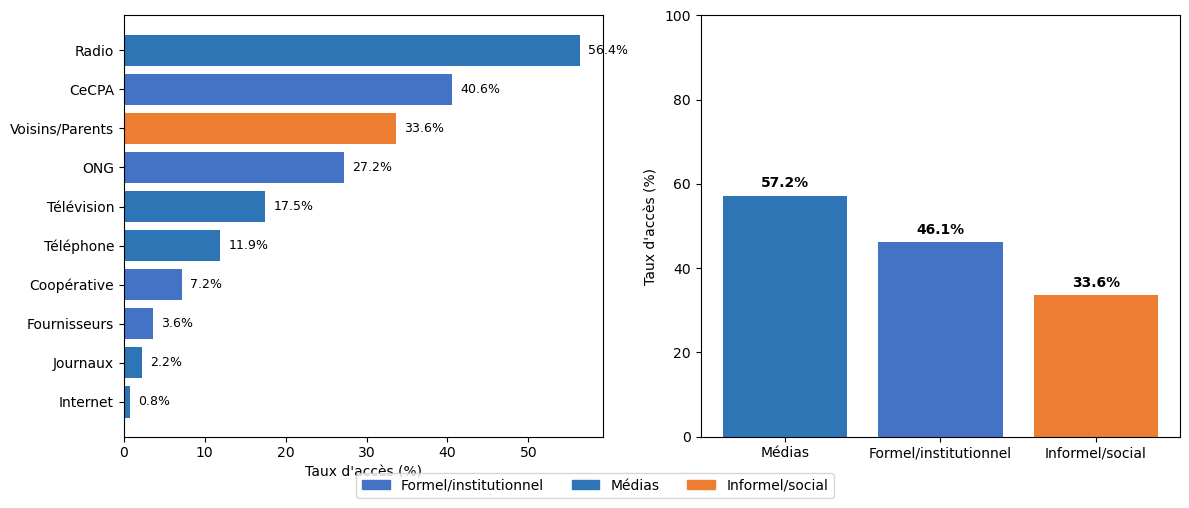

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

sources_labels = {
    'cecp':  ('CeCPA', 'Formel/institutionnel'),
    'ong':   ('ONG', 'Formel/institutionnel'),
    'coop':  ('Coopérative', 'Formel/institutionnel'),
    'four':  ('Fournisseurs', 'Formel/institutionnel'),
    'vois':  ('Voisins/Parents', 'Informel/social'),
    'radio': ('Radio', 'Médias'),
    'tele':  ('Télévision', 'Médias'),
    'fone':  ('Téléphone', 'Médias'),
    'int':   ('Internet', 'Médias'),
    'jour':  ('Journaux', 'Médias'),
}

rows = []
for suffix, (label, categorie) in sources_labels.items():
    col = 's' + suffix
    n_acces = int((df[col] == 1).sum())
    pct = round(n_acces / len(df) * 100, 1)
    rows.append({'Source': label, 'Catégorie': categorie, '% accès': pct})

tab2 = pd.DataFrame(rows).sort_values('% accès', ascending=False).reset_index(drop=True)

cat_map = {
    'Formel/institutionnel': ['scecp','song','scoop','sfour'],
    'Médias':                ['sradio','stele','sfone','sint','sjour'],
    'Informel/social':       ['svois'],
}
rows_cat = []
for cat, cols in cat_map.items():
    n = int((df[cols] == 1).any(axis=1).sum())
    rows_cat.append({'Catégorie': cat, '% accès': round(n/len(df)*100, 1)})
tab2_cat = pd.DataFrame(rows_cat).sort_values('% accès', ascending=False)

color_map = {'Formel/institutionnel':'#4472C4', 'Médias':'#2E75B6', 'Informel/social':'#ED7D31'}
colors_src = [color_map[c] for c in tab2['Catégorie']]

fig, axes = plt.subplots(1, 2, figsize=(12,5))

axes[0].barh(tab2['Source'][::-1], tab2['% accès'][::-1], color=colors_src[::-1])
axes[0].set_xlabel("Taux d'accès (%)")
for i, v in enumerate(tab2['% accès'][::-1]):
    axes[0].text(v + 1, i, f'{v}%', va='center', fontsize=9)

colors_cat = [color_map[c] for c in tab2_cat['Catégorie']]
axes[1].bar(tab2_cat['Catégorie'], tab2_cat['% accès'], color=colors_cat)
axes[1].set_ylabel("Taux d'accès (%)")
axes[1].set_ylim(0, 100)
for i, v in enumerate(tab2_cat['% accès']):
    axes[1].text(i, v + 2, f'{v}%', ha='center', fontsize=10, fontweight='bold')

handles = [mpatches.Patch(color=c, label=l) for l, c in color_map.items()]
fig.legend(handles=handles, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.savefig('Figure2_Acces_Sources.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
vars_quant = [
    ('agep',   'Âge (années)'),
    ('educ',   "Niveau d'instruction (années)"),
    ('supdis', 'Superficie disponible (ha)'),
    ('tailm',  'Taille du ménage'),
    ('nactif', "Nombre d'actifs agricoles"),
    ('parna',  'Part revenu non agricole (Sur 10)'),
    ('parpv',  'Part revenu végétal (Sur 10)'),
]

html_quant = """
<table style="border-collapse:collapse; font-family:Arial; font-size:13px; margin-top:15px;">
<tr>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Variable</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Oui (moy±ET)</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Non (moy±ET)</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Ensemble (moy±ET)</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Test</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Statistique (t)</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">p-value</th>
</tr>
"""

for var, label in vars_quant:
    g0 = df[df['utilisation_info']==0][var].dropna()
    g1 = df[df['utilisation_info']==1][var].dropna()
    g_all = df[var].dropna()
    t_stat, p_val = stats.ttest_ind(g1, g0, equal_var=False)
    sig = '***' if p_val < 0.01 else '**' if p_val < 0.05 else '*' if p_val < 0.10 else 'ns'
    html_quant += "<tr>"
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:left; font-weight:bold;">{label}</td>'
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:center;">{g1.mean():.2f} ({g1.std():.2f})</td>'
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:center;">{g0.mean():.2f} ({g0.std():.2f})</td>'
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:center;">{g_all.mean():.2f} ({g_all.std():.2f})</td>'
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:center;">t Student</td>'
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:center;">{t_stat:.3f}</td>'
    html_quant += f'<td style="border:1px solid black; padding:6px; text-align:center;">{p_val:.4f} {sig}</td>'
    html_quant += "</tr>"

html_quant += "</table>"
HTML(html_quant)

Variable,Oui (moy±ET),Non (moy±ET),Ensemble (moy±ET),Test,Statistique (t),p-value
Âge (années),43.56 (12.53),43.57 (12.71),43.56 (12.57),t Student,-0.012,0.9904 ns
Niveau d'instruction (années),3.37 (3.64),1.36 (2.64),2.72 (3.48),t Student,5.955,0.0000 ***
Superficie disponible (ha),8.83 (12.74),5.47 (6.80),7.74 (11.26),t Student,3.252,0.0013 ***
Taille du ménage,10.50 (8.29),10.79 (7.03),10.60 (7.89),t Student,-0.349,0.7275 ns
Nombre d'actifs agricoles,5.95 (5.79),6.07 (5.20),5.99 (5.60),t Student,-0.194,0.8465 ns
Part revenu non agricole (Sur 10),2.82 (1.91),2.59 (1.77),2.74 (1.87),t Student,1.142,0.2546 ns
Part revenu végétal (Sur 10),6.22 (1.75),6.90 (1.78),6.44 (1.79),t Student,-3.390,0.0008 ***


In [11]:
import pandas as pd
from scipy import stats

n_total = len(df)
rows = []

def add_qual_block(var, label, order, mod_labels):
    tab = pd.crosstab(df[var], df['utilisation_info'])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    sig = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else 'ns'
    first = True
    for k in order:
        if k not in tab.index:
            continue
        n_mod = int(tab.loc[k].sum())
        n_oui = int(tab.loc[k, 1]) if 1 in tab.columns else 0
        n_non = int(tab.loc[k, 0]) if 0 in tab.columns else 0
        rows.append([
            label if first else '', mod_labels[k],
            round(n_oui/n_mod*100, 1), round(n_non/n_mod*100, 1), round(n_mod/n_total*100, 1),
            'Chi²' if first else '', round(chi2, 3) if first else None,
            p if first else None, sig if first else ''
        ])
        first = False

add_qual_block('realisme_percu', 'Réalisme perçu', [0,1], {0:'Non réaliste', 1:'Réaliste'})
add_qual_block('accessibilite', 'Accessibilité de la source', [0,1], {0:'Sans accès', 1:'Avec accès'})
add_qual_block('freq_reception', 'Fréquence de réception', [1,2,3,4],
               {1:'Quotidien', 2:'Hebdomadaire', 3:'Mensuel', 4:'Saisonnier'})
add_qual_block('sex', 'Sexe', [0,1], {0:'Masculin', 1:'Féminin'})
add_qual_block('alpha', 'Alphabétisation', [0,1], {0:'Non', 1:'Oui'})
add_qual_block('poscel', "Possession d'un téléphone", [0,1], {0:'Non', 1:'Oui'})
add_qual_block('posradio', "Possession d'une radio", [0,1], {0:'Non', 1:'Oui'})
add_qual_block('postele', "Possession d'une télévision", [0,1], {0:'Non', 1:'Oui'})
add_qual_block('acred', 'Accès au crédit formel', [0,1], {0:'Non', 1:'Oui'})
add_qual_block('crefor', 'Accès au crédit informel', [0,1], {0:'Non', 1:'Oui'})
add_qual_block('vulg', 'Contact avec la vulgarisation', [0,1], {0:'Non', 1:'Oui'})
add_qual_block('group', "Membre d'un groupement/coopérative", [0,1], {0:'Non', 1:'Oui'})
add_qual_block('proch', 'A des proches dans le village', [0,1], {0:'Non', 1:'Oui'})
add_qual_block('smetri_bin', 'Situation matrimoniale (marié)', [0,1], {0:'Non', 1:'Oui'})
add_qual_block('infocc', 'Connaissance du changement climatique', [0,1], {0:'Non', 1:'Oui'})

tab3 = pd.DataFrame(rows, columns=[
    'Caractéristiques', 'Modalité', 'Oui (%)', 'Non (%)', 'Ensemble (%)',
    'Test', 'Statistique (χ²)', 'p-value', 'Sig.'
])

styled = tab3.style.hide(axis="index").format(
    {'Oui (%)': '{:.1f}', 'Non (%)': '{:.1f}', 'Ensemble (%)': '{:.1f}',
     'Statistique (χ²)': '{:.3f}', 'p-value': '{:.4f}'}, na_rep=''
).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#1F4E79'), ('color', 'white'),
                                   ('font-weight', 'bold'), ('border', '1px solid black'),
                                   ('text-align', 'center'), ('padding', '6px')]},
    {'selector': 'td', 'props': [('border', '1px solid #ccc'), ('text-align', 'center'), ('padding', '5px')]}
]).set_properties(subset=['Caractéristiques'], **{'text-align': 'left', 'font-weight': 'bold'})

styled

Caractéristiques,Modalité,Oui (%),Non (%),Ensemble (%),Test,Statistique (χ²),p-value,Sig.
Réalisme perçu,Non réaliste,11.3,88.7,31.9,Chi²,239.500,0.0000,***
,Réaliste,93.9,6.1,68.1,,,,
Accessibilité de la source,Sans accès,0.0,100.0,23.3,Chi²,223.563,0.0000,***
,Avec accès,88.0,12.0,76.7,,,,
Fréquence de réception,Quotidien,94.0,6.0,23.3,Chi²,151.531,0.0000,***
,Hebdomadaire,94.6,5.4,10.3,,,,
,Mensuel,25.0,75.0,33.3,,,,
,Saisonnier,83.2,16.8,33.1,,,,
Sexe,Masculin,69.3,30.7,87.8,Chi²,3.191,0.0740,*
,Féminin,54.5,45.5,12.2,,,,


In [13]:
import pandas as pd
from scipy import stats
from IPython.display import HTML

def calc_bloc(var, order, mod_labels):
    tab = pd.crosstab(df[var], df['utilisation_info'])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    sig = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else 'ns'
    lignes = []
    for k in order:
        n_mod = int(tab.loc[k].sum())
        n_oui = int(tab.loc[k, 1]) if 1 in tab.columns else 0
        n_non = int(tab.loc[k, 0]) if 0 in tab.columns else 0
        lignes.append((mod_labels[k], round(n_oui/n_mod*100,1), round(n_non/n_mod*100,1), round(n_mod/len(df)*100,1)))
    return lignes, round(chi2,3), f"{p:.4f} {sig}"

sections = {
    "Caractéristiques de l'information climatique": [
        ('Réalisme perçu', 'realisme_percu', [0,1], {0:'Non réaliste', 1:'Réaliste'}),
        ('Accessibilité de la source', 'accessibilite', [0,1], {0:'Sans accès', 1:'Avec accès'}),
        ('Fréquence de réception', 'freq_reception', [1,2,3,4], {1:'Quotidien',2:'Hebdomadaire',3:'Mensuel',4:'Saisonnier'}),
    ],
    "Caractéristiques socio-économiques du producteur": [
        ('Sexe', 'sex', [0,1], {0:'Masculin', 1:'Féminin'}),
        ('Alphabétisation', 'alpha', [0,1], {0:'Non', 1:'Oui'}),
        ("Possession d'un téléphone", 'poscel', [0,1], {0:'Non', 1:'Oui'}),
        ("Possession d'une radio", 'posradio', [0,1], {0:'Non', 1:'Oui'}),
        ("Possession d'une télévision", 'postele', [0,1], {0:'Non', 1:'Oui'}),
        ('Accès au crédit formel', 'acred', [0,1], {0:'Non', 1:'Oui'}),
        ('Accès au crédit informel', 'crefor', [0,1], {0:'Non', 1:'Oui'}),
        ('Contact avec la vulgarisation', 'vulg', [0,1], {0:'Non', 1:'Oui'}),
        ("Membre d'un groupement/coopérative", 'group', [0,1], {0:'Non', 1:'Oui'}),
        ('A des proches dans le village', 'proch', [0,1], {0:'Non', 1:'Oui'}),
        ('Situation matrimoniale (marié)', 'smetri_bin', [0,1], {0:'Non', 1:'Oui'}),
        ('Connaissance du changement climatique', 'infocc', [0,1], {0:'Non', 1:'Oui'}),
    ]
}

html = """
<table style="border-collapse:collapse; font-family:Arial; font-size:13px;">
<tr>
  <th rowspan="3" style="border:1px solid black; background:#D9E1F2; padding:6px;">Caractéristiques</th>
  <th colspan="3" style="border:1px solid black; background:#D9E1F2; padding:6px;">Utilisation de l'information climatique</th>
  <th rowspan="3" style="border:1px solid black; background:#D9E1F2; padding:6px;">Test</th>
  <th rowspan="3" style="border:1px solid black; background:#D9E1F2; padding:6px;">Statistique du test (χ²)</th>
  <th rowspan="3" style="border:1px solid black; background:#D9E1F2; padding:6px;">p-value</th>
</tr>
<tr><th colspan="3" style="border:1px solid black; background:#D9E1F2; padding:6px;">Pourcentages</th></tr>
<tr>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Oui</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Non</th>
  <th style="border:1px solid black; background:#D9E1F2; padding:6px;">Ensemble</th>
</tr>
"""

for section_title, variables in sections.items():
    html += f'<tr><td colspan="7" style="border:1px solid black; background:#F4B6B6; font-weight:bold; text-align:center; padding:6px;">{section_title}</td></tr>'
    for label, var, order, mod_labels in variables:
        lignes, chi2, pval = calc_bloc(var, order, mod_labels)
        n = len(lignes)
        for i, (mod, pct_oui, pct_non, ens) in enumerate(lignes):
            html += "<tr>"
            if i == 0:
                html += f'<td rowspan="{n}" style="border:1px solid black; background:#D9D9D9; font-weight:bold; padding:6px;">{label}</td>'
            html += f'<td style="border:1px solid black; padding:6px; text-align:left;">&nbsp;&nbsp;&nbsp;{mod}</td>'
            html += f'<td style="border:1px solid black; padding:6px; text-align:center;">{pct_oui}</td>'
            html += f'<td style="border:1px solid black; padding:6px; text-align:center;">{pct_non}</td>'
            html += f'<td style="border:1px solid black; padding:6px; text-align:center;">{ens}</td>'
            if i == 0:
                html += f'<td rowspan="{n}" style="border:1px solid black; text-align:center; padding:6px;">Chi²</td>'
                html += f'<td rowspan="{n}" style="border:1px solid black; text-align:center; padding:6px;">{chi2}</td>'
                html += f'<td rowspan="{n}" style="border:1px solid black; text-align:center; padding:6px;">{pval}</td>'
            html += "</tr>"

html += "</table>"
HTML(html)

In [6]:
# ============================================================
# BLOC 3 — VIF (multicolinéarité), zone traitée en dummies
# ============================================================
vars_candidats = ['utilisation_info','realisme_percu','freq_reception',
    'sex','agep','educ','alpha','smetri_bin','group','vulg',
    'acred','crefor','supdis','parpv','parna','tailm','nactif',
    'poscel','posradio','postele','zone']

df_cand = df[vars_candidats].dropna().copy()
print("N =", len(df_cand))

X_vif = df_cand.drop(columns=['utilisation_info']).copy()
X_vif = pd.get_dummies(X_vif, columns=['zone'], drop_first=True)  # zone en dummies, pas en numérique
X_vif = X_vif.astype(float)
X_vif_c = sm.add_constant(X_vif)

vif = pd.DataFrame()
vif['Variable'] = X_vif.columns
vif['VIF'] = [variance_inflation_factor(X_vif_c.values, i) for i in range(1, X_vif_c.shape[1])]
vif['Statut'] = vif['VIF'].apply(
    lambda v: 'PROBLEME SERIEUX' if v > 10
    else ('Colinearite moderee' if v > 5
    else 'OK'))
print(vif.sort_values('VIF', ascending=False).to_string(index=False))

N = 360
      Variable      VIF Statut
         parna 3.340431     OK
         tailm 3.200408     OK
        nactif 3.185234     OK
     zone_Nord 3.110602     OK
      zone_Sud 2.928192     OK
         parpv 2.924405     OK
        supdis 1.585882     OK
freq_reception 1.474374     OK
realisme_percu 1.432513     OK
         group 1.397756     OK
          vulg 1.390019     OK
         acred 1.339072     OK
        crefor 1.295980     OK
          agep 1.294756     OK
         alpha 1.290513     OK
        poscel 1.288902     OK
           sex 1.286923     OK
          educ 1.245400     OK
    smetri_bin 1.243676     OK
      posradio 1.221834     OK
       postele 1.212213     OK


In [4]:
df_mod = df_cand.copy()
df_mod['freq_reception'] = df_mod['freq_reception'].map({1:'Quotidien',2:'Hebdomadaire',3:'Mensuel',4:'Saisonnier'})
df_mod = pd.get_dummies(df_mod, columns=['freq_reception','zone'], drop_first=False)
df_mod = df_mod.astype(float)
df_mod = df_mod.drop(columns=[c for c in df_mod.columns if c in ['freq_reception_Quotidien','zone_Sud']])

Y = df_mod['utilisation_info']
X = df_mod.drop('utilisation_info', axis=1)
Xc = sm.add_constant(X)

modele1 = sm.Logit(Y, Xc).fit(disp=0)
print(modele1.summary())
print("Pseudo R2 Modele 1:", modele1.prsquared)
print("AUC Modele 1:", roc_auc_score(Y, modele1.predict()))

                           Logit Regression Results                           
Dep. Variable:       utilisation_info   No. Observations:                  360
Model:                          Logit   Df Residuals:                      336
Method:                           MLE   Df Model:                           23
Date:                Mon, 13 Jul 2026   Pseudo R-squ.:                  0.7619
Time:                        07:14:27   Log-Likelihood:                -54.059
converged:                       True   LL-Null:                       -227.01
Covariance Type:            nonrobust   LLR p-value:                 2.179e-59
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                           5.5895      3.004      1.861      0.063      -0.298      11.477
realisme_percu                  5.8391      0.873      6.686      0.000       4.

In [5]:
infl = modele1.get_influence()
resid_std = infl.resid_studentized
leverage = infl.hat_matrix_diag
cooks = infl.cooks_distance[0]
dfbetas = infl.dfbetas

n, k = Xc.shape
seuil_lev = 2*k/n
seuil_cook = 4/n
seuil_dfbeta = 2/np.sqrt(n)

influentes = (
    (np.abs(resid_std) > 2) &
    (leverage > seuil_lev) &
    (cooks > seuil_cook) &
    (np.abs(dfbetas).max(axis=1) > seuil_dfbeta)
)
print(f"Seuils: levier>{seuil_lev:.4f}, Cook>{seuil_cook:.4f}, dfbeta>{seuil_dfbeta:.4f}")
print("Nb observations influentes:", influentes.sum())

Seuils: levier>0.1333, Cook>0.0111, dfbeta>0.1054
Nb observations influentes: 1


In [7]:
df_mod2 = df_mod[~influentes].copy()
Y2 = df_mod2['utilisation_info']
X2 = df_mod2.drop('utilisation_info', axis=1)
X2c = sm.add_constant(X2)

modele2 = sm.Logit(Y2, X2c).fit(disp=0)
print(modele2.summary())

OR2 = np.exp(modele2.params)
print("\n--- Odds Ratios ---")
print(OR2)

pred2 = modele2.predict()
pred2_class = (pred2 > 0.5).astype(int)
cm2 = confusion_matrix(Y2, pred2_class)
print("\nMatrice de confusion:\n", cm2)
print("Taux classification:", round((cm2[0,0]+cm2[1,1])/cm2.sum()*100,1), "%")
print("AUC Modele 2:", roc_auc_score(Y2, pred2))
print("Pseudo R2 Modele 2:", modele2.prsquared)

                           Logit Regression Results                           
Dep. Variable:       utilisation_info   No. Observations:                  359
Model:                          Logit   Df Residuals:                      335
Method:                           MLE   Df Model:                           23
Date:                Mon, 13 Jul 2026   Pseudo R-squ.:                  0.7737
Time:                        07:20:30   Log-Likelihood:                -51.115
converged:                       True   LL-Null:                       -225.88
Covariance Type:            nonrobust   LLR p-value:                 3.950e-60
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                           5.1166      3.177      1.610      0.107      -1.110      11.343
realisme_percu                  6.1502      0.953      6.456      0.000       4.